# ShopSphere E-Commerce Analytics
### Data Engineering Assignment

**Pipeline:**
1. Load raw data
2. Clean & fix issues
3. Build dimensional model
4. Compute KPIs

---
## STEP 1 — Install & Import

In [73]:
!pip install python-dateutil thefuzz -q
# sqlite3 is built into Python — no install needed

In [74]:
import pandas as pd
import numpy as np
import json
import re
import os
import sqlite3
from dateutil import parser as dateparser
from thefuzz import process

pd.set_option('display.max_columns', None)
print('All imports done!')

All imports done!


---
## STEP 2 — Load Raw Files

In [75]:
BASE = '/content'
# Correcting the file mappings
customers = pd.read_excel('/content/customers.xlsx')
orders = pd.read_excel('/content/orders.xlsx')
items = pd.read_excel('/content/order_items.xlsx')
payments = pd.read_excel('/content/payments.xlsx')
products = pd.read_excel('/content/products.xlsx')
returns = pd.read_excel('/content/returns.xlsx')

# Loading JSON files

with open("/content/suppliers_json.txt") as f:
    suppliers = pd.DataFrame(json.load(f))

for name, df in [('customers', customers), ('orders', orders),
                 ('order_items', items),    ('payments', payments),
                 ('products', products),    ('returns', returns),
                 ('suppliers', suppliers)]:
    print(f'{name:<15} {df.shape[0]:>4} rows   {df.shape[1]:>2} cols')

customers        163 rows   13 cols
orders           323 rows    8 cols
order_items      802 rows    7 cols
payments         329 rows    6 cols
products          75 rows    9 cols
returns           68 rows    6 cols
suppliers         19 rows    6 cols


---
## STEP 3 — Quick Look at the Data

In [76]:
customers.head()

,customer_id,first_name,last_name,email,phone,address_line1,city,state,zip_code,country,signup_date,customer_segment,is_active
0,C0143,Chatura,Gokhale,chatura.gokhale143@example.com,6676650618,"H.No. 49, Manda Zila",BANGALORE,Karnataka,919015,India,2023-05-19 00:00:00,Silver,yes
1,C0015,Chaitanya,Sarin,chaitanya.sarin15@example.com,(595) 148-4656,"80, Mangat Road",BANGALORE,Karnataka,823662,India,2021-01-02 00:00:00,Bronze,True
2,C0056,Caleb,Iyengar,caleb.iyengar56@example.com,-8740344963,"75, Loke Circle",Mumbai,Maharashtra,NaN,India,08/28/2023,Silverr,yes
3,C0140,Krishna,Baria,krishna.baria140@example.com,4057202590,"818, Sagar Street",Kolkata,West Bengal,798515,India,2022-04-14 00:00:00,Glod,yes
4,C0001,Isaac,Bakshi,isaac.bakshi1@example.com,8196001338,"H.No. 265, Dugal Road",Bangalore,Karnataka,838637,India,2023-03-23 00:00:00,bronze,Y


In [77]:
orders.head()

,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city
0,O00140,C0112,2025-09-06 00:00:00,Complted,Debit Card,web,PROMO19,Chennai
1,O00225,C0066,10/14/2025,completed,NetBanking,web,NaN,Delhi
2,O00188,C0082,10/24/2024,PENDING,COD,APP,NaN,Hyderabad
3,O00183,C0114,2024-07-30 00:00:00,Pending,UPI,app,NaN,Ahmedabad
4,O00233,C0078,02/26/2025,completed,Credit Card,web,PROMO17,Hyderabad


In [78]:
items.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total
0,OI000136,O00309,P054,4,20481.04,10,73731.74
1,OI000768,O00160,P059,1,18828.50,0,18828.50
2,OI000646,O00066,P055,5,5471.28,0,27356.40
3,OI000594,O00136,P062,4,8493.72,0,33974.88
4,OI000129,O00285,P062,1,8493.72,0,4246.86


In [79]:
payments.head()

,payment_id,order_id,payment_date,amount,payment_status,payment_method
0,PM00167,O00028,09/23/2024,67330.43,Success,Credit Card
1,PM00141,O00020,2024-11-03 00:00:00,"â‚¹210,054.96",SUCCESS,UPI
2,PM00066,O00210,2025-04-09 00:00:00,75706.13,Success,Debit Card
3,PM00204,O00231,2024-07-20 00:00:00,27808.29,SUCCESS,Credit Card
4,PM00035,O00104,2024-03-02 00:00:00,131635.23,success,Debit Card


In [80]:
products.head()

,product_id,product_name,category,sub_category,unit_price,cost_price,supplier_id,is_active,launch_date
0,P023,Footwear Item 23,Fashion,Footwear,3019.36,2515.11,S92,True,2024-06-26 00:00:00
1,P052,Womenswear Item 52,fashion,Womenswear,17637.28,11253.70,S001,yes,2025-01-24 00:00:00
2,P003,Staples Item 3 (Revised),GROCERY,Staples,9543.98,10602.65,S006,Y,2021-04-28 00:00:00
3,P059,NaN,NaN,Cookware,18828.5,15780.42,S006,Y,2020-11-01 00:00:00
4,P024,Footwear Item 24,FASHION,Footwear,11175.62,7441.33,S012,Y,2023-03-25 00:00:00


In [81]:
returns.head()

,return_id,order_item_id,return_date,return_reason,refund_amount,return_status
0,R0018,OI000526,2024-01-21 00:00:00,wrong item,18739.92,Approved
1,R0045,OI000620,2025-12-11 00:00:00,size issue,6474.73,APPROVED
2,R0044,OI000640,2024-04-02 00:00:00,Wrong Item,25783.29,Rejected
3,R0002,OI000546,2024-06-18 00:00:00,not as described,18753.51,approved
4,R0053,OI000045,03/21/2024,wrong item,NaN,Approved


In [82]:
suppliers.head()

,supplier_id,supplier_name,country,rating,contract_start_date,is_preferred
0,S001,"Baral, Din and Bhalla",None,4.3,2018-12-11,N
1,S002,Varughese Group,Germany,2.5,2019-03-02,False
2,S003,"Bahl, Mander and Chada",Vietnam,2.9,2022-03-12,False
3,S004,"Sinha, Subramaniam and Garde",China,9.4,2019-07-08,true
4,S005,Dhar-Gopal,Germany,4.5,2019-07-15,Y


---
## STEP 4 — Find Data Quality Issues

In [83]:
# Check missing values in every file
for name, df in [('customers', customers), ('orders', orders),
                 ('order_items', items),    ('payments', payments),
                 ('products', products),    ('returns', returns),
                 ('suppliers', suppliers)]:
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    print(f'--- {name} ---')
    print(nulls if len(nulls) else 'No nulls')
    print()

--- customers ---
email          6
phone          2
zip_code       4
signup_date    3
dtype: int64

--- orders ---
promo_code    228
dtype: int64

--- order_items ---
unit_price    5
dtype: int64

--- payments ---
payment_date    10
dtype: int64

--- products ---
product_name    2
category        5
dtype: int64

--- returns ---
refund_amount    4
dtype: int64

--- suppliers ---
country    3
dtype: int64



In [84]:
# Check inconsistent category values
print('customer_segment:\n', customers['customer_segment'].value_counts())
print('\norder_status:\n',    orders['order_status'].value_counts())
print('\nchannel:\n',         orders['channel'].value_counts())
print('\nproduct category:\n',products['category'].value_counts())
print('\nreturn_status:\n',   returns['return_status'].value_counts())
print('\npayment_status:\n',  payments['payment_status'].value_counts())

customer_segment:
 customer_segment
Platinum    16
PLATINUM    16
Glod        15
platinum    14
SILVER      14
bronze      12
Bronze      11
Broze       11
silver      11
GOLD         9
Silverr      9
Gold         8
Silver       7
gold         7
BRONZE       3
Name: count, dtype: int64

order_status:
 order_status
Complted     46
completed    45
COMPLETE     42
Completed    34
Returned     31
returned     29
pending      23
PENDING      16
Pending      14
cancelled    12
Canceled     12
Cancelled    10
Cancled       9
Name: count, dtype: int64

channel:
 channel
app         48
App         36
APP         34
web         33
store       31
Store       31
WEB         29
Web         28
In-store    28
Instore     25
Name: count, dtype: int64

product category:
 category
Home and Kitchen    9
GROCERY             8
fashion             8
Grocery             6
sports              6
Fashion             6
grocery             5
electronics         4
Sports              4
home & kitchen      4
Electr

In [85]:
# Check messy amounts in payments
print('Sample payment amounts:')
print(payments['amount'].head(10).tolist())

Sample payment amounts:
[67330.43, 'â‚¹210,054.96', 75706.13, 27808.29, 131635.23, 143472.24, 45144.5, 'â‚¹102,114.63', 73792.99, 166130.39]


In [86]:
# Check referential integrity — orphan rows
print('Orders with unknown customer_id:  ',
      orders[~orders['customer_id'].isin(customers['customer_id'])].shape[0])

print('Order items with unknown order_id:',
      items[~items['order_id'].isin(orders['order_id'])].shape[0])

print('Order items with unknown product:  ',
      items[~items['product_id'].isin(products['product_id'])].shape[0])

print('Payments with unknown order_id:   ',
      payments[~payments['order_id'].isin(orders['order_id'])].shape[0])

print('Returns with unknown order_item_id:',
      returns[~returns['order_item_id'].isin(items['order_item_id'])].shape[0])

print('Products with unknown supplier_id: ',
      products[~products['supplier_id'].isin(suppliers['supplier_id'])].shape[0])

Orders with unknown customer_id:   15
Order items with unknown order_id: 10
Order items with unknown product:   8
Payments with unknown order_id:    8
Returns with unknown order_item_id: 6
Products with unknown supplier_id:  4


In [87]:
# Check line_total mismatch in order_items
items['expected'] = (items['quantity'] * items['unit_price'] * (1 - items['discount_pct']/100)).round(2)
mismatch = items[abs(items['line_total'] - items['expected']) > 0.5]
print(f'line_total mismatches: {len(mismatch)}')
mismatch[['order_item_id','quantity','unit_price','discount_pct','line_total','expected']].head()

line_total mismatches: 46


,order_item_id,quantity,unit_price,discount_pct,line_total,expected
4,OI000129,1,8493.72,0,4246.86,8493.72
13,OI000120,2,26274.11,-10,49920.81,57803.04
85,OI000125,5,4516.10,150,22580.50,-11290.25
95,OI000496,5,15706.03,20,50259.30,62824.12
137,OI000190,1,8493.72,0,16987.44,8493.72


---
## STEP 5 — Clean the Data

We define helper functions first, then clean each file one by one.

In [88]:
# ---------- Helper functions ----------

def parse_date(val):
    """Parse any messy date string → YYYY-MM-DD"""
    if pd.isna(val) or str(val).strip() in ('', 'NA', 'N/A', 'null', 'NaT'):
        return None
    try:
        return dateparser.parse(str(val), dayfirst=True).strftime('%Y-%m-%d')
    except:
        return None

def normalize_bool(val):
    """Convert yes/no/true/false/Y/N/1/0 → True/False"""
    if pd.isna(val):
        return None
    v = str(val).strip().lower()
    if v in ('true', 'yes', 'y', '1', 't'):
        return True
    if v in ('false', 'no', 'n', '0', 'f'):
        return False
    return None

def clean_amount(val):
    """Strip currency symbols and commas → float"""
    if pd.isna(val):
        return None
    cleaned = re.sub(r'[₹$€£,\s]', '', str(val))
    try:
        return float(cleaned)
    except:
        return None

print('Helper functions ready!')

Helper functions ready!


In [89]:
# ---------- Clean CUSTOMERS ----------
cust = customers.copy()

# Fix segment typos: Silverr→Silver, Glod→Gold, bronze→Bronze, Broze→Bronze
valid_segments = ['Gold', 'Silver', 'Bronze', 'Platinum']
def fix_segment(val):
    if pd.isna(val) or str(val).strip() == '':
        return None
    match, score = process.extractOne(str(val).strip(), valid_segments)
    return match if score >= 60 else None

cust['customer_segment'] = cust['customer_segment'].apply(fix_segment)

# Normalize is_active
cust['is_active'] = cust['is_active'].apply(normalize_bool)

# Fix signup_date (mixed formats: 19-May-2023, 08/28/2023, 2021-01-02)
cust['signup_date'] = cust['signup_date'].apply(parse_date)

# Title case city names (BANGALORE → Bangalore)
cust['city'] = cust['city'].str.title()

# Replace N/A zip codes
cust['zip_code'] = cust['zip_code'].replace({'N/A': None, 'NA': None})

# Remove exact duplicate rows
cust = cust.drop_duplicates()

# Deduplicate on email — keep earliest signup
cust = cust.sort_values('signup_date').drop_duplicates(subset=['email'], keep='first')

# Add surrogate key
cust = cust.reset_index(drop=True)
cust.insert(0, 'customer_sk', cust.index + 1)

# SCD Type 2 columns
cust['scd_start_date'] = cust['signup_date']
cust['scd_end_date']   = '9999-12-31'
cust['is_current']     = True

print(f'Customers: {len(customers)} raw → {len(cust)} clean')
cust[['customer_sk','customer_id','first_name','customer_segment','is_active','signup_date']].head()

Customers: 163 raw → 157 clean


,customer_sk,customer_id,first_name,customer_segment,is_active,signup_date
0,1,C0024,Nidhi,Bronze,True,2021-01-12
1,2,C0086,Ekta,Bronze,True,2021-01-14
2,3,C0037,Gautam,Gold,True,2021-01-16
3,4,C0064,Darika,Platinum,True,2021-01-26
4,5,C0015,Chaitanya,Bronze,True,2021-02-01


<Axes: title={'center': 'Top 10 cities'}, xlabel='city'>

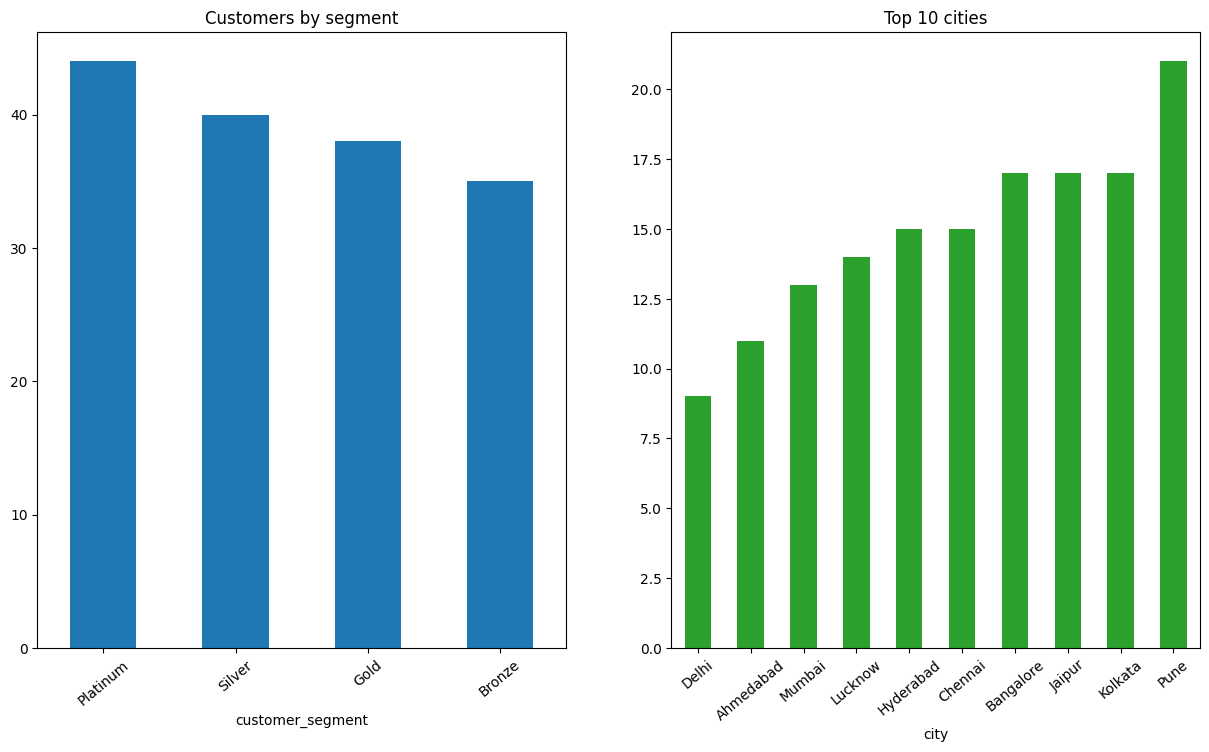

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
cust['customer_segment'].value_counts(dropna=False).plot(kind='bar', ax=ax[0], rot=40, title='Customers by segment')
cust['city'].value_counts().head(10).sort_values().plot(kind='bar', ax=ax[1], rot = 40, title='Top 10 cities', color='tab:green')

In [91]:
# ---------- Clean SUPPLIERS ----------
supp = suppliers.copy()

# Normalize is_preferred
supp['is_preferred'] = supp['is_preferred'].apply(normalize_bool)

# Standardize dates
supp['contract_start_date'] = supp['contract_start_date'].apply(parse_date)

# Normalize supplier_id to zero-padded format (S92 → S092)
supp['supplier_id'] = supp['supplier_id'].apply(
    lambda x: 'S' + str(x).lstrip('S').zfill(3) if pd.notna(x) else x
)

# Normalize rating scale — S004 has rating 9.4 (out of 10), others are out of 5
supp['rating_norm'] = supp['rating'].apply(
    lambda r: round(r / 2, 2) if pd.notna(r) and r > 5 else r
)

# Remove duplicates
supp = supp.drop_duplicates(subset=['supplier_id'], keep='last')

# Surrogate key
supp = supp.reset_index(drop=True)
supp.insert(0, 'supplier_sk', supp.index + 1)

print(f'Suppliers: {len(suppliers)} raw → {len(supp)} clean')
supp.head()

Suppliers: 19 raw → 18 clean


,supplier_sk,supplier_id,supplier_name,country,rating,contract_start_date,is_preferred,rating_norm
0,1,S001,"Baral, Din and Bhalla",None,4.3,2018-11-12,False,4.30
1,2,S002,Varughese Group,Germany,2.5,2019-02-03,False,2.50
2,3,S003,"Bahl, Mander and Chada",Vietnam,2.9,2022-12-03,False,2.90
3,4,S005,Dhar-Gopal,Germany,4.5,2019-07-15,True,4.50
4,5,S006,"Lalla, Ganesh and Oommen",Germany,7.5,2022-12-05,False,3.75


In [92]:
# ---------- Clean PRODUCTS ----------
prod = products.copy()

# Normalize supplier_id format (S92 → S092)
prod['supplier_id'] = prod['supplier_id'].apply(
    lambda x: 'S' + str(x).lstrip('S').zfill(3) if pd.notna(x) else x
)

# Normalize category to Title Case
prod['category'] = prod['category'].str.strip().str.title()
prod['category'] = prod['category'].replace({'Grocery': 'Grocery', 'Home & Kitchen': 'Home & Kitchen'})

# Normalize is_active
prod['is_active'] = prod['is_active'].apply(normalize_bool)

# Fix launch_date
prod['launch_date'] = prod['launch_date'].apply(parse_date)

# Clean unit_price and cost_price (some have ₹ symbol)
prod['unit_price'] = prod['unit_price'].apply(clean_amount)
prod['cost_price'] = prod['cost_price'].apply(clean_amount)

# Flag products sold at a loss (cost > price)
prod['is_loss_item'] = prod['cost_price'] > prod['unit_price']

# Keep latest version per product_id (handles Revised duplicates)
prod = prod.drop_duplicates(subset=['product_id'], keep='last')

# Surrogate key
prod = prod.reset_index(drop=True)
prod.insert(0, 'product_sk', prod.index + 1)

# Join supplier_sk
prod = prod.merge(supp[['supplier_sk','supplier_id']], on='supplier_id', how='left')

print(f'Products: {len(products)} raw → {len(prod)} clean')
print(f'Loss items (cost > price): {prod["is_loss_item"].sum()}')
prod[['product_sk','product_id','product_name','category','unit_price','cost_price','is_loss_item']].head()

Products: 75 raw → 70 clean
Loss items (cost > price): 12


,product_sk,product_id,product_name,category,unit_price,cost_price,is_loss_item
0,1,P023,Footwear Item 23,Fashion,3019.36,2515.11,False
1,2,P052,Womenswear Item 52,Fashion,17637.28,11253.70,False
2,3,P059,NaN,NaN,18828.50,15780.42,False
3,4,P024,Footwear Item 24,Fashion,11175.62,7441.33,False
4,5,P032,Womenswear Item 32,Fashion,23243.35,16113.29,False


Text(0, 0.5, 'Product')

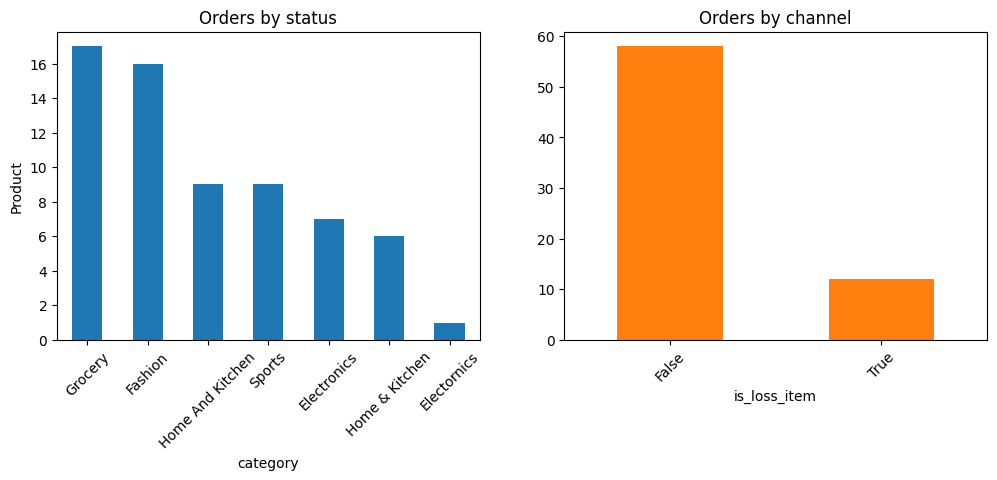

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
prod['category'].value_counts().plot(kind='bar', ax=ax[0], rot=45 , title='Orders by status')
prod['is_loss_item'].value_counts().plot(kind='bar', ax=ax[1], rot=45, title='Orders by channel', color='tab:orange')
ax[0].set_ylabel('Product')

In [93]:
# ---------- Clean ORDERS ----------
ord_ = orders.copy()
order_rejects = []

# Normalize order_status with a robust lowercase mapping dictionary
status_map = {
    'completed': 'Completed',
    'complted': 'Completed',
    'complete': 'Completed',
    'cancelled': 'Cancelled',
    'canceled': 'Cancelled',
    'cancled': 'Cancelled',
    'pending': 'Pending',
    'returned': 'Returned',
    'refunded': 'Returned'
}

# Normalize case and map
ord_['order_status'] = ord_['order_status'].str.strip().str.lower().map(status_map)

# Normalize channel
channel_map = {
    'web': 'Web', 'app': 'App',
    'store': 'Store', 'instore': 'Store', 'in-store': 'Store'
}
ord_['channel'] = ord_['channel'].str.strip().str.lower().map(channel_map)

# Standardize order_date
ord_['order_date'] = ord_['order_date'].apply(parse_date)

# Replace "NA" promo codes
ord_['promo_code'] = ord_['promo_code'].replace({'NA': None, 'N/A': None, '': None})

# Reject orders with unknown customer_id
valid_custs = cust['customer_id'].unique()
bad = ord_[~ord_['customer_id'].isin(valid_custs)].copy()
bad['reject_reason'] = 'customer_id not found'
order_rejects.append(bad)
ord_ = ord_[ord_['customer_id'].isin(valid_custs)]

# Remove duplicates
ord_ = ord_.drop_duplicates(subset=['order_id'], keep='last')

print(f'Orders: {len(orders)} raw → {len(ord_)} clean, {len(bad)} rejected')
display(ord_['order_status'].value_counts())
ord_.head()

Orders: 323 raw → 298 clean, 22 rejected


,count
order_status,
Completed,154
Returned,56
Pending,50
Cancelled,38


,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city
0,O00140,C0112,2025-06-09,Completed,Debit Card,Web,PROMO19,Chennai
1,O00225,C0066,2025-10-14,Completed,NetBanking,Web,NaN,Delhi
2,O00188,C0082,2024-10-24,Pending,COD,App,NaN,Hyderabad
3,O00183,C0114,2024-07-30,Pending,UPI,App,NaN,Ahmedabad
4,O00233,C0078,2025-02-26,Completed,Credit Card,Web,PROMO17,Hyderabad


In [94]:
ord_['order_status'].value_counts()

,count
order_status,
Completed,154
Returned,56
Pending,50
Cancelled,38


Text(0, 0.5, 'Orders')

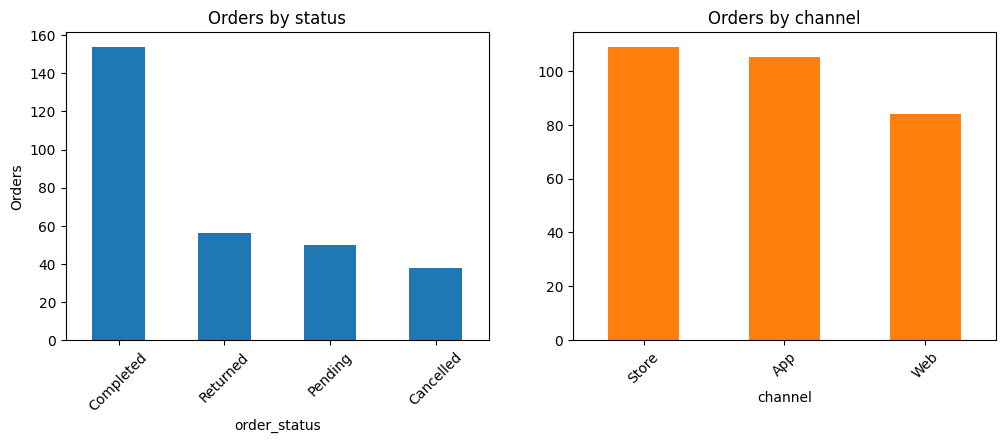

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ord_['order_status'].value_counts().plot(kind='bar', ax=ax[0], rot=45 , title='Orders by status')
ord_['channel'].value_counts().plot(kind='bar', ax=ax[1], rot=45, title='Orders by channel', color='tab:orange')
ax[0].set_ylabel('Orders')

In [96]:
# ---------- Clean ORDER ITEMS ----------
oi = items.copy()
items_rejects = []

# Reject zero/negative quantity
bad_qty = oi[oi['quantity'] <= 0].copy()
bad_qty['reject_reason'] = 'zero or negative quantity'
items_rejects.append(bad_qty)
oi = oi[oi['quantity'] > 0]

# Reject orphaned order_ids
bad_ord = oi[~oi['order_id'].isin(ord_['order_id'])].copy()
bad_ord['reject_reason'] = 'order_id not found'
items_rejects.append(bad_ord)
oi = oi[oi['order_id'].isin(ord_['order_id'])]

# Reject orphaned product_ids
bad_prod = oi[~oi['product_id'].isin(prod['product_id'])].copy()
bad_prod['reject_reason'] = 'product_id not found'
items_rejects.append(bad_prod)
oi = oi[oi['product_id'].isin(prod['product_id'])]

# Recompute line_total
oi['line_total'] = (oi['quantity'] * oi['unit_price'] * (1 - oi['discount_pct']/100)).round(2)

# Drop expected column from earlier
oi = oi.drop(columns=['expected'], errors='ignore')

# Join surrogate keys
oi = oi.merge(prod[['product_sk','product_id']], on='product_id', how='left')
ord_cust = ord_[['order_id','customer_id']].merge(
    cust[cust['is_current']==True][['customer_sk','customer_id']], on='customer_id', how='left'
)
oi = oi.merge(ord_cust[['order_id','customer_sk']], on='order_id', how='left')

# Remove duplicates
oi = oi.drop_duplicates(subset=['order_item_id'], keep='last')

total_rejected = sum(len(r) for r in items_rejects)
print(f'Order items: {len(items)} raw → {len(oi)} clean, {total_rejected} rejected')
oi.head()

Order items: 802 raw → 712 clean, 86 rejected


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,product_sk,customer_sk
0,OI000136,O00309,P054,4,20481.04,10,73731.74,67,46
1,OI000768,O00160,P059,1,18828.50,0,18828.50,3,33
2,OI000646,O00066,P055,5,5471.28,0,27356.40,34,17
3,OI000594,O00136,P062,4,8493.72,0,33974.88,40,50
4,OI000129,O00285,P062,1,8493.72,0,8493.72,40,128


In [97]:
# ---------- Clean PAYMENTS ----------
pay = payments.copy()
pay_rejects = []

# Strip currency symbols from amount
pay['amount'] = pay['amount'].apply(clean_amount)

# Normalize payment_status
pay['payment_status'] = pay['payment_status'].str.strip().str.title()

# Standardize payment_date
pay['payment_date'] = pay['payment_date'].apply(parse_date)

# Reject orphaned order_ids
bad = pay[~pay['order_id'].isin(ord_['order_id'])].copy()
bad['reject_reason'] = 'order_id not found'
pay_rejects.append(bad)
pay = pay[pay['order_id'].isin(ord_['order_id'])]

# Deduplicate — same payment_id, keep latest
pay = pay.sort_values('payment_date').drop_duplicates(subset=['payment_id'], keep='last')

print(f'Payments: {len(payments)} raw → {len(pay)} clean, {len(bad)} rejected')
pay.head()

Payments: 329 raw → 295 clean, 30 rejected


,payment_id,order_id,payment_date,amount,payment_status,payment_method
100,PM00073,O00047,2024-01-01,49866.55,Success,Debit Card
111,PM00257,O00176,2024-01-03,137941.77,Failed,NetBanking
149,PM00323,O00296,2024-01-12,44738.62,Pending,UPI
183,PM00312,O00024,2024-01-13,98196.55,Succeded,NetBanking
75,PM00296,O00062,2024-01-13,103988.90,Success,COD


In [98]:
# ---------- Clean RETURNS ----------
ret = returns.copy()
ret_rejects = []

# Normalize return_status
ret['return_status'] = ret['return_status'].str.strip().str.title()

# Normalize return_reason to lowercase
ret['return_reason'] = ret['return_reason'].str.strip().str.lower()

# Standardize return_date
ret['return_date'] = ret['return_date'].apply(parse_date)

# Reject orphaned order_item_ids
bad = ret[~ret['order_item_id'].isin(oi['order_item_id'])].copy()
bad['reject_reason'] = 'order_item_id not found'
ret_rejects.append(bad)
ret = ret[ret['order_item_id'].isin(oi['order_item_id'])]

# Remove duplicates
ret = ret.drop_duplicates(subset=['return_id'], keep='last')

print(f'Returns: {len(returns)} raw → {len(ret)} clean, {len(bad)} rejected')
ret.head()

Returns: 68 raw → 50 clean, 15 rejected


,return_id,order_item_id,return_date,return_reason,refund_amount,return_status
0,R0018,OI000526,2024-01-21,wrong item,18739.92,Approved
2,R0044,OI000640,2024-02-04,wrong item,25783.29,Rejected
4,R0053,OI000045,2024-03-21,wrong item,NaN,Approved
6,R0014,OI000500,2025-04-03,not as described,40241.54,Pending
8,R0005,OI000302,2024-09-26,size issue,NaN,Rejected


Text(0, 0.5, 'Return')

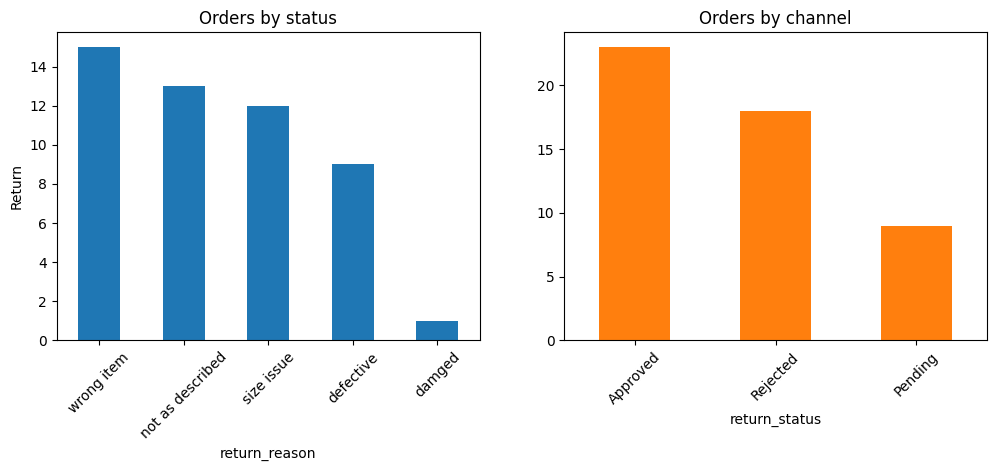

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ret['return_reason'].value_counts().plot(kind='bar', ax=ax[0], rot=45 , title='Orders by status')
ret['return_status'].value_counts().plot(kind='bar', ax=ax[1], rot=45, title='Orders by channel', color='tab:orange')
ax[0].set_ylabel('Return')

---
## STEP 6 — Data Quality Scorecard

In [99]:
raw_counts    = [163, 323, 802, 329, 75, 68, 19]
clean_counts  = [len(cust), len(ord_), len(oi), len(pay), len(prod), len(ret), len(supp)]
names         = ['customers','orders','order_items','payments','products','returns','suppliers']

scorecard = pd.DataFrame({
    'File'    : names,
    'Raw Rows': raw_counts,
    'Clean'   : clean_counts,
    'Rejected': [r - c for r, c in zip(raw_counts, clean_counts)],
})
scorecard['Pass Rate %'] = (scorecard['Clean'] / scorecard['Raw Rows'] * 100).round(1)
scorecard

,File,Raw Rows,Clean,Rejected,Pass Rate %
0,customers,163,157,6,96.3
1,orders,323,298,25,92.3
2,order_items,802,712,90,88.8
3,payments,329,295,34,89.7
4,products,75,70,5,93.3
5,returns,68,50,18,73.5
6,suppliers,19,18,1,94.7


---
## STEP 7 — Load Cleaned Data into SQLite

We load all cleaned dataframes into a local SQLite database so we can run SQL queries on them.

In [100]:
# Create an in-memory SQLite database and load all cleaned tables
con = sqlite3.connect(':memory:')

cust.to_sql('dim_customers',    con, index=False, if_exists='replace')
prod.to_sql('dim_products',     con, index=False, if_exists='replace')
supp.to_sql('dim_suppliers',    con, index=False, if_exists='replace')
ord_.to_sql('fact_orders',      con, index=False, if_exists='replace')
oi.to_sql(  'fact_order_items', con, index=False, if_exists='replace')
pay.to_sql( 'fact_payments',    con, index=False, if_exists='replace')
ret.to_sql( 'fact_returns',     con, index=False, if_exists='replace')

# Quick helper so we can just write sql(query) to get a DataFrame back
def sql(query):
    return pd.read_sql_query(query, con)

print('SQLite loaded! Tables ready:')
sql("SELECT name FROM sqlite_master WHERE type='table'")

SQLite loaded! Tables ready:


,name
0,dim_customers
1,dim_products
2,dim_suppliers
3,fact_orders
4,fact_order_items
5,fact_payments
6,fact_returns


---
## STEP 8 — KPI 1: Net Revenue by Product Category per Month

In [101]:
kpi1 = sql("""
    SELECT
        strftime('%Y-%m', o.order_date)               AS year_month,
        p.category,
        ROUND(SUM(oi.line_total), 2)                  AS gross_revenue,
        ROUND(COALESCE(SUM(r.refund_amount), 0), 2)   AS total_refunds,
        ROUND(SUM(oi.line_total)
              - COALESCE(SUM(r.refund_amount), 0), 2) AS net_revenue
    FROM fact_order_items oi
    JOIN fact_orders o       ON oi.order_id      = o.order_id
    JOIN dim_products p      ON oi.product_id    = p.product_id
    LEFT JOIN fact_returns r ON oi.order_item_id = r.order_item_id
                             AND r.return_status = 'Approved'
    WHERE o.order_status = 'Completed'
    GROUP BY year_month, p.category
    ORDER BY year_month, net_revenue DESC
""")

print('KPI 1 — Net Revenue by Category per Month')
kpi1.head(20)

KPI 1 — Net Revenue by Category per Month


,year_month,category,gross_revenue,total_refunds,net_revenue
0,2020-12,Home And Kitchen,21122.18,0.00,21122.18
1,2021-12,None,88376.90,0.00,88376.90
2,2021-12,Electornics,16084.14,0.00,16084.14
3,2022-05,None,81924.16,0.00,81924.16
4,2022-05,Grocery,17582.77,0.00,17582.77
5,2022-05,Fashion,9607.25,0.00,9607.25
6,2024-01,Grocery,241491.55,0.00,241491.55
7,2024-01,Home & Kitchen,203127.81,0.00,203127.81
8,2024-01,Sports,104144.29,0.00,104144.29
9,2024-01,Electronics,73366.10,0.00,73366.10


---
## STEP 9 — KPI 2: Top 10 Customers by Net Lifetime Value

In [102]:
kpi2 = sql("""
    SELECT
        c.customer_id,
        c.first_name || ' ' || c.last_name              AS customer_name,
        c.customer_segment,
        COUNT(DISTINCT o.order_id)                       AS total_orders,
        ROUND(SUM(oi.line_total), 2)                     AS gross_spend,
        ROUND(COALESCE(SUM(r.refund_amount), 0), 2)      AS total_refunds,
        ROUND(SUM(oi.line_total)
              - COALESCE(SUM(r.refund_amount), 0), 2)    AS net_ltv
    FROM fact_order_items oi
    JOIN fact_orders o        ON oi.order_id      = o.order_id
    JOIN dim_customers c      ON oi.customer_sk   = c.customer_sk
                              AND c.is_current    = 1
    LEFT JOIN fact_returns r  ON oi.order_item_id = r.order_item_id
                              AND r.return_status = 'Approved'
    WHERE o.order_status = 'Completed'
    GROUP BY c.customer_id, customer_name, c.customer_segment
    ORDER BY net_ltv DESC
    LIMIT 10
""")

print('KPI 2 — Top 10 Customers by Net LTV')
kpi2

KPI 2 — Top 10 Customers by Net LTV


,customer_id,customer_name,customer_segment,total_orders,gross_spend,total_refunds,net_ltv
0,C0118,Utkarsh Bhat,Gold,3,532447.01,0.00,532447.01
1,C0107,Eesha Sethi,Silver,2,463604.51,0.00,463604.51
2,C0061,Yadavi Bhakta,Platinum,2,341730.61,0.00,341730.61
3,C0148,Ucchal Thaker,Bronze,3,329199.64,0.00,329199.64
4,C0142,Zansi Prasad,Platinum,4,328510.36,0.00,328510.36
5,C0001,Isaac Bakshi,Bronze,4,377880.04,75816.05,302063.99
6,C0085,Chakrika Koshy,Silver,3,291047.36,0.00,291047.36
7,C0033,Hamsini Rao,Gold,2,268013.97,0.00,268013.97
8,C0129,Siddharth Bains,Platinum,3,284905.07,19128.89,265776.18
9,C0037,Gautam Rana,Gold,2,259380.42,0.00,259380.42


---
## STEP 10 — KPI 3: Customer Segment Profile

In [103]:
kpi3 = sql("""
    WITH order_vals AS (
        SELECT oi.customer_sk,
               o.order_id,
               SUM(oi.line_total) AS order_value
        FROM fact_order_items oi
        JOIN fact_orders o ON oi.order_id = o.order_id
        WHERE o.order_status = 'Completed'
        GROUP BY oi.customer_sk, o.order_id
    )
    SELECT
        c.customer_segment                   AS segment,
        COUNT(DISTINCT c.customer_id)        AS customer_count,
        COUNT(DISTINCT ov.order_id)          AS total_orders,
        ROUND(AVG(ov.order_value), 2)        AS avg_order_value,
        ROUND(SUM(ov.order_value), 2)        AS total_revenue
    FROM dim_customers c
    LEFT JOIN order_vals ov ON c.customer_sk = ov.customer_sk
    WHERE c.is_current = 1
    GROUP BY c.customer_segment
    ORDER BY avg_order_value DESC
""")

print('KPI 3 — Customer Segment Profile')
kpi3

KPI 3 — Customer Segment Profile


,segment,customer_count,total_orders,avg_order_value,total_revenue
0,Gold,37,33,97727.93,3127293.63
1,Silver,39,35,89983.11,3149408.80
2,Platinum,42,50,78399.20,3919960.07
3,Bronze,34,35,75569.43,2644930.04


---
## STEP 11 — KPI 4: Month-over-Month Growth by Channel

In [104]:
# SQLite has window functions (LAG) since version 3.25 (2018) — should be fine
kpi4 = sql("""
    WITH monthly AS (
        SELECT
            o.channel,
            strftime('%Y-%m', o.order_date)    AS year_month,
            COUNT(DISTINCT o.order_id)          AS order_count,
            ROUND(SUM(oi.line_total), 2)        AS revenue
        FROM fact_orders o
        JOIN fact_order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status != 'Cancelled'
        GROUP BY o.channel, year_month
    )
    SELECT *,
        LAG(order_count) OVER (PARTITION BY channel ORDER BY year_month) AS prev_orders,
        LAG(revenue)     OVER (PARTITION BY channel ORDER BY year_month) AS prev_revenue,
        ROUND(100.0 * (order_count - LAG(order_count) OVER (PARTITION BY channel ORDER BY year_month))
              / NULLIF(LAG(order_count) OVER (PARTITION BY channel ORDER BY year_month), 0), 1)
              AS mom_order_pct,
        ROUND(100.0 * (revenue - LAG(revenue) OVER (PARTITION BY channel ORDER BY year_month))
              / NULLIF(LAG(revenue) OVER (PARTITION BY channel ORDER BY year_month), 0), 1)
              AS mom_revenue_pct
    FROM monthly
    ORDER BY channel, year_month
""")

print('KPI 4 — MoM Order Volume & Revenue Growth by Channel')
kpi4.head(20)

KPI 4 — MoM Order Volume & Revenue Growth by Channel


,channel,year_month,order_count,revenue,prev_orders,prev_revenue,mom_order_pct,mom_revenue_pct
0,App,2020-12,1,21122.18,NaN,NaN,NaN,NaN
1,App,2021-09,1,69278.72,1.0,21122.18,0.0,228.0
2,App,2022-05,1,109114.18,1.0,69278.72,0.0,57.5
3,App,2024-01,7,729390.95,1.0,109114.18,600.0,568.5
4,App,2024-02,6,512756.63,7.0,729390.95,-14.3,-29.7
5,App,2024-03,5,332161.90,6.0,512756.63,-16.7,-35.2
6,App,2024-04,5,338385.63,5.0,332161.90,0.0,1.9
7,App,2024-05,2,248097.95,5.0,338385.63,-60.0,-26.7
8,App,2024-06,9,609103.44,2.0,248097.95,350.0,145.5
9,App,2024-07,2,141584.69,9.0,609103.44,-77.8,-76.8


---
## STEP 12 — KPI 5: Product Return Rate (Top 10 & Bottom 10)

In [105]:
kpi5 = sql("""
    WITH vol AS (
        SELECT product_id, SUM(quantity) AS total_qty
        FROM fact_order_items
        GROUP BY product_id
        HAVING SUM(quantity) >= 3
    ),
    ret AS (
        SELECT oi.product_id, COUNT(r.return_id) AS return_count
        FROM fact_returns r
        JOIN fact_order_items oi ON r.order_item_id = oi.order_item_id
        WHERE r.return_status = 'Approved'
        GROUP BY oi.product_id
    )
    SELECT
        p.product_id,
        p.product_name,
        p.category,
        v.total_qty,
        COALESCE(r.return_count, 0)                                     AS returns,
        ROUND(100.0 * COALESCE(r.return_count, 0) / v.total_qty, 2)    AS return_rate_pct
    FROM vol v
    JOIN dim_products p ON v.product_id = p.product_id
    LEFT JOIN ret r     ON v.product_id = r.product_id
    ORDER BY return_rate_pct DESC
""")

print('Top 10 — Highest Return Rate')
print(kpi5.head(10).to_string(index=False))
print('\nBottom 10 — Lowest Return Rate')
print(kpi5.tail(10).to_string(index=False))

Top 10 — Highest Return Rate
product_id        product_name         category  total_qty  returns  return_rate_pct
      P026    Footwear Item 26          Fashion         12        1             8.33
      P042     Staples Item 42          Grocery         35        2             5.71
      P044   Beverages Item 44          Grocery         39        2             5.13
      P018 Team Sports Item 18           Sports         23        1             4.35
      P029   Furniture Item 29 Home And Kitchen         26        1             3.85
      P045    Footwear Item 45          Fashion         26        1             3.85
      P013  Appliances Item 13 Home And Kitchen         27        1             3.70
      P052  Womenswear Item 52          Fashion         27        1             3.70
      P058      Snacks Item 58          Grocery         28        1             3.57
      P009    Furniture Item 9   Home & Kitchen         30        1             3.33

Bottom 10 — Lowest Return Rate
prod

---
## STEP 13 — KPI 6: Supplier Performance Scorecard

In [106]:
kpi6 = sql("""
    WITH rev AS (
        SELECT p.supplier_id, ROUND(SUM(oi.line_total), 2) AS total_revenue
        FROM fact_order_items oi
        JOIN dim_products p ON oi.product_id = p.product_id
        GROUP BY p.supplier_id
    ),
    ret AS (
        SELECT p.supplier_id,
               ROUND(100.0 * COUNT(r.return_id)
                     / NULLIF(COUNT(oi.order_item_id), 0), 2) AS return_rate
        FROM fact_order_items oi
        JOIN dim_products p ON oi.product_id = p.product_id
        LEFT JOIN fact_returns r ON oi.order_item_id = r.order_item_id
        GROUP BY p.supplier_id
    ),
    max_rev AS (
        SELECT MAX(total_revenue) AS max_revenue FROM rev
    )
    SELECT
        s.supplier_id,
        s.supplier_name,
        s.rating_norm,
        rv.total_revenue,
        rt.return_rate,
        ROUND(
            0.5 * (rv.total_revenue / mx.max_revenue) +
            0.3 * (s.rating_norm   / 5.0) +
            0.2 * (1.0 - rt.return_rate / 100.0)
        , 4) AS composite_score
    FROM dim_suppliers s
    JOIN rev rv ON s.supplier_id = rv.supplier_id
    JOIN ret rt ON s.supplier_id = rt.supplier_id
    JOIN max_rev mx
    ORDER BY composite_score DESC
""")

print('KPI 6 — Supplier Performance Scorecard')
kpi6

KPI 6 — Supplier Performance Scorecard


,supplier_id,supplier_name,rating_norm,total_revenue,return_rate,composite_score
0,S006,"Lalla, Ganesh and Oommen",3.75,3231721.36,8.75,0.9075
1,S015,"Chaudhari, Sandal and Desai",4.10,2858390.33,1.89,0.8845
2,S007,"Biswas, Karpe and Radhakrishnan",4.20,2507990.84,2.99,0.8340
3,S004,"Amble, Prashad and Jha",4.70,2119193.92,4.88,0.8001
4,S001,"Baral, Din and Bhalla",4.30,1876722.42,9.38,0.7296
5,S012,"Zacharia, Agarwal and Sankar",3.00,1727621.21,9.43,0.6284
6,S018,"Amble, Virk and Dalal",5.00,780501.32,4.76,0.6112
7,S005,Dhar-Gopal,4.50,938973.77,6.25,0.6028
8,S010,"Barad, Wali and Thakur",4.90,734632.98,3.33,0.6010
9,S014,Raj-Palla,2.50,1698206.49,11.76,0.5892


---
## STEP 14 — KPI 7: Customer Repeat-Purchase Rate (90 days)

In [107]:
# SQLite has no INTERVAL — use date() with modifier instead
kpi7 = sql("""
    WITH first_ord AS (
        SELECT oi.customer_sk,
               MIN(o.order_date) AS first_date
        FROM fact_orders o
        JOIN fact_order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'Completed'
        GROUP BY oi.customer_sk
    ),
    repeat_cust AS (
        SELECT DISTINCT fo.customer_sk
        FROM first_ord fo
        JOIN fact_order_items oi2 ON oi2.customer_sk = fo.customer_sk
        JOIN fact_orders o2       ON o2.order_id = oi2.order_id
                                  AND o2.order_status = 'Completed'
        WHERE o2.order_date > fo.first_date
          AND o2.order_date <= date(fo.first_date, '+90 days')
    )
    SELECT
        COUNT(DISTINCT fo.customer_sk)                              AS total_customers,
        COUNT(DISTINCT rc.customer_sk)                              AS repeat_customers,
        ROUND(100.0 * COUNT(DISTINCT rc.customer_sk)
              / NULLIF(COUNT(DISTINCT fo.customer_sk), 0), 2)      AS repeat_rate_pct
    FROM first_ord fo
    LEFT JOIN repeat_cust rc ON fo.customer_sk = rc.customer_sk
""")

print('KPI 7 — Customer Repeat-Purchase Rate (90-day window)')
kpi7

KPI 7 — Customer Repeat-Purchase Rate (90-day window)


,total_customers,repeat_customers,repeat_rate_pct
0,95,7,7.37


---
## STEP 15 — KPI 8: Payment Reconciliation & Anomaly Report

In [108]:
kpi8 = sql("""
    WITH order_total AS (
        SELECT order_id, ROUND(SUM(line_total), 2) AS expected_total
        FROM fact_order_items
        GROUP BY order_id
    ),
    pay_summary AS (
        SELECT
            order_id,
            ROUND(SUM(CASE WHEN payment_status = 'Success' THEN amount ELSE 0 END), 2) AS paid_total,
            COUNT(*)                   AS payment_rows,
            COUNT(DISTINCT payment_id) AS distinct_payments
        FROM fact_payments
        GROUP BY order_id
    )
    SELECT
        ot.order_id,
        ot.expected_total,
        COALESCE(ps.paid_total, 0)                               AS paid_total,
        ROUND(ot.expected_total - COALESCE(ps.paid_total, 0), 2) AS variance,
        CASE
            WHEN ps.order_id IS NULL                                 THEN 'No payment recorded'
            WHEN ps.payment_rows > ps.distinct_payments              THEN 'Duplicate payment rows'
            WHEN COALESCE(ps.paid_total, 0) < ot.expected_total - 1 THEN 'Under-payment'
            WHEN COALESCE(ps.paid_total, 0) > ot.expected_total + 1 THEN 'Over-payment'
            ELSE 'OK'
        END AS anomaly_flag
    FROM order_total ot
    LEFT JOIN pay_summary ps ON ot.order_id = ps.order_id
    WHERE anomaly_flag != 'OK'
    ORDER BY ABS(variance) DESC
""")

print(f'KPI 8 — Payment Anomalies: {len(kpi8)} orders flagged')
kpi8.head(20)

KPI 8 — Payment Anomalies: 227 orders flagged


,order_id,expected_total,paid_total,variance,anomaly_flag
0,O00146,270507.92,0.00,270507.92,Under-payment
1,O00298,246362.98,0.00,246362.98,Under-payment
2,O00194,233365.67,0.00,233365.67,Under-payment
3,O00082,224837.10,0.00,224837.10,No payment recorded
4,O00043,100493.15,320939.45,-220446.30,Over-payment
5,O00085,217987.79,0.00,217987.79,Under-payment
6,O00220,217054.78,0.00,217054.78,Under-payment
7,O00253,216532.73,0.00,216532.73,Under-payment
8,O00294,215198.38,0.00,215198.38,Under-payment
9,O00297,203529.85,0.00,203529.85,Under-payment


---
## STEP 16 — Stretch KPI: Margin Risk Report

In [109]:
stretch = sql("""
    SELECT
        p.product_id,
        p.product_name,
        p.category,
        ROUND(p.unit_price, 2)                                      AS unit_price,
        ROUND(p.cost_price, 2)                                      AS cost_price,
        ROUND(p.cost_price - p.unit_price, 2)                       AS loss_per_unit,
        SUM(oi.quantity)                                            AS units_sold,
        ROUND(SUM(oi.line_total), 2)                                AS revenue_at_risk,
        ROUND(SUM((p.cost_price - p.unit_price) * oi.quantity), 2)  AS total_loss_exposure
    FROM dim_products p
    JOIN fact_order_items oi ON p.product_id = oi.product_id
    WHERE p.cost_price > p.unit_price
    GROUP BY p.product_id, p.product_name, p.category, p.unit_price, p.cost_price
    ORDER BY total_loss_exposure DESC
""")

print(f'Stretch KPI — {len(stretch)} products sold at a loss')
stretch

Stretch KPI — 12 products sold at a loss


,product_id,product_name,category,unit_price,cost_price,loss_per_unit,units_sold,revenue_at_risk,total_loss_exposure
0,P065,Footwear Item 65,Fashion,15706.03,23290.69,7584.66,65,921943.98,493002.90
1,P003,Staples Item 3,Grocery,-70.38,10602.65,10673.03,25,-1572.98,266825.75
2,P013,Appliances Item 13,Home And Kitchen,15622.68,24940.49,9317.81,27,333544.22,251580.87
3,P060,Staples Item 60 (Revised),Grocery,11569.57,18576.25,7006.68,28,301387.29,196187.04
4,P039,Fitness Item 39 (Revised),Sports,5818.64,14577.41,8758.77,19,100371.54,166416.63
5,P001,Accessories Item 1 (Revised),Electronics,10660.79,16799.61,6138.82,14,144986.74,85943.48
6,P040,Footwear Item 40,Fashion,0.00,1563.28,1563.28,44,100256.05,68784.32
7,P020,Beverages Item 20,Grocery,3634.57,5171.78,1537.21,40,133388.72,61488.40
8,P006,Furniture Item 6,Home And Kitchen,2863.09,4549.93,1686.84,27,71720.40,45544.68
9,P028,Appliances Item 28,Home And Kitchen,7218.53,9457.58,2239.05,20,132460.02,44781.00


---
## STEP 17 — Save All Outputs

In [110]:
OUT = '/content/output'
os.makedirs(OUT, exist_ok=True)

# Silver layer
cust.to_csv(f'{OUT}/dim_customers.csv', index=False)
prod.to_csv(f'{OUT}/dim_products.csv',  index=False)
supp.to_csv(f'{OUT}/dim_suppliers.csv', index=False)
ord_.to_csv(f'{OUT}/fact_orders.csv',   index=False)
oi.to_csv(  f'{OUT}/fact_order_items.csv', index=False)
pay.to_csv( f'{OUT}/fact_payments.csv', index=False)
ret.to_csv( f'{OUT}/fact_returns.csv',  index=False)

# KPI outputs
kpi1.to_csv(f'{OUT}/kpi1_net_revenue.csv',      index=False)
kpi2.to_csv(f'{OUT}/kpi2_top_customers.csv',    index=False)
kpi3.to_csv(f'{OUT}/kpi3_segments.csv',         index=False)
kpi4.to_csv(f'{OUT}/kpi4_mom_growth.csv',       index=False)
kpi5.to_csv(f'{OUT}/kpi5_return_rate.csv',      index=False)
kpi6.to_csv(f'{OUT}/kpi6_suppliers.csv',        index=False)
kpi7.to_csv(f'{OUT}/kpi7_repeat_rate.csv',      index=False)
kpi8.to_csv(f'{OUT}/kpi8_payment_anomalies.csv',index=False)
stretch.to_csv(f'{OUT}/kpi_stretch_margin.csv', index=False)
scorecard.to_csv(f'{OUT}/data_quality_scorecard.csv', index=False)

print('All outputs saved to:', OUT)
for f in sorted(os.listdir(OUT)):
    print(' ', f)

All outputs saved to: /content/output
  data_quality_scorecard.csv
  dim_customers.csv
  dim_products.csv
  dim_suppliers.csv
  fact_order_items.csv
  fact_orders.csv
  fact_payments.csv
  fact_returns.csv
  kpi1_net_revenue.csv
  kpi2_top_customers.csv
  kpi3_segments.csv
  kpi4_mom_growth.csv
  kpi5_return_rate.csv
  kpi6_suppliers.csv
  kpi7_repeat_rate.csv
  kpi8_payment_anomalies.csv
  kpi_stretch_margin.csv


---
## Done!

**What this notebook produced:**

| Output | Description |
|---|---|
| `dim_customers.csv` | Cleaned customers with SCD columns |
| `dim_products.csv` | Cleaned products with loss flag |
| `dim_suppliers.csv` | Cleaned suppliers with normalized rating |
| `fact_orders.csv` | Cleaned orders |
| `fact_order_items.csv` | Cleaned line items with recomputed totals |
| `fact_payments.csv` | Cleaned payments |
| `fact_returns.csv` | Cleaned returns |
| `kpi1` to `kpi8` | All 8 KPI results |
| `kpi_stretch_margin.csv` | Bonus margin risk report |
| `data_quality_scorecard.csv` | Before/after row counts per file |